### **Load the data**

In [20]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Metro_Interstate_Traffic_Volume.csv")
print(df.shape)
df.head()

(48204, 9)


,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     object 
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  object 
 6   weather_description  48204 non-null  object 
 7   date_time            48204 non-null  object 
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), object(4)
memory usage: 3.3+ MB


In [22]:
df.isnull().sum()

,0
holiday,48143
temp,0
rain_1h,0
snow_1h,0
clouds_all,0
weather_main,0
weather_description,0
date_time,0
traffic_volume,0


### **Clean and create features**

In [23]:
df["date_time"] = pd.to_datetime(df["date_time"])
df["hour"] = df["date_time"].dt.hour
df["weekday"] = df["date_time"].dt.weekday
df["month"] = df["date_time"].dt.month

# Convert temperature from Kelvin to Celsius
df["temp_c"] = df["temp"] - 273.15

# Turn weather text into numbers
df = pd.get_dummies(df, columns=["weather_main"], drop_first=True)

### **Explore the data**

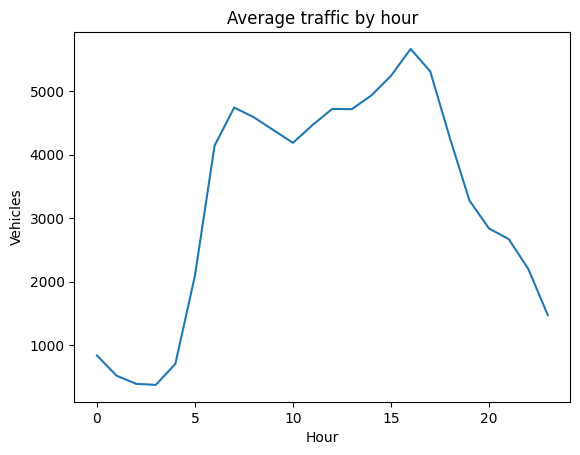

In [24]:
df.groupby("hour")["traffic_volume"].mean().plot(kind="line")
plt.title("Average traffic by hour")
plt.xlabel("Hour"); plt.ylabel("Vehicles")
plt.show()

In [25]:
hourly = df.groupby("hour")["traffic_volume"].mean()

print("Busiest hours:")
print(hourly.sort_values(ascending=False).head(3))

print("Quietest hours:")
print(hourly.sort_values().head(3))

Busiest hours:
hour
16    5663.756539
17    5310.076048
15    5240.524302
Name: traffic_volume, dtype: float64
Quietest hours:
hour
3    371.090864
2    388.353640
1    516.449000
Name: traffic_volume, dtype: float64


### **Split into train and test sets**

In [26]:
X = df.drop(columns=["traffic_volume", "date_time"], errors="ignore")
X = X.select_dtypes(include=[np.number, "bool"])
y = df["traffic_volume"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [27]:
# Fill numeric columns with the median
num_cols = X.select_dtypes(include=[np.number]).columns
X[num_cols] = X[num_cols].fillna(X[num_cols].median())

# Check that nothing is missing now
print(X.isnull().sum().sum())   # should print 0

0


### **Train two models**

In [28]:
print(X.isnull().sum()[X.isnull().sum() > 0])

Series([], dtype: int64)


In [29]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    print(name, "MAE:", round(mean_absolute_error(y_test, pred), 1),
          "R2:", round(r2_score(y_test, pred), 3))

Linear Regression MAE: 1589.9 R2: 0.17
Random Forest MAE: 251.9 R2: 0.947
